In [1]:
import myhda_ur as hda

In [2]:
hdata = hda.load_scifate()

In [3]:
top_hvg = hdata.get_highly_variable_genes(n=2000)

In [ ]:
# Initialize a temporary subset object for the selected cells 

subset_traj_ = hdata[top_hvg, :]    # 2000 genes x allcells

In [ ]:
# Get top HDTs
# Make sure to keep all cells available when using get_highly_dynamic_trajectories

top_traj = subset_traj_.get_highly_dynamic_trajectories(n=300)

# Trajectory

## Total RNA

### Expression-distance clusters

gene x cell expression matrix -> distance matrix -> cluster 

In [7]:
# Compute trajectory-trajectory similarity of HDTs using X values

hdata.compute_similarity(
    data=subset_traj_,
    key="X",
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation"
)

Similarity "correlation_X_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_X_trajectory']
  clusters: []
  embeddings: []
  trajectories: Yes

In [8]:
sim_traj = hdata.similarities["correlation_X_trajectory"]

In [9]:
# Cluster using Graph-based Clustering - Spectral

hdata.cluster_spectral(
        sim = sim_traj,                                               
        kind = "trajectory",
        k = 6
    )

Cluster "spectral_k6_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_X_trajectory']
  clusters: ['spectral_k6_trajectory']
  embeddings: []
  trajectories: Yes

In [10]:
c1_spec_traj = hdata.clusters["spectral_k6_trajectory"]

In [13]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data = subset_traj_,
    key = "X",
    kind = "trajectory",
    trajectory_id=top_traj,
    id = "exp_dist"
)

UMAP embedding "umap_trajectory_exp_dist" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr']
  similarities: ['correlation_X_trajectory']
  clusters: ['spectral_k6_trajectory']
  embeddings: ['umap_trajectory_exp_dist']
  trajectories: Yes

In [14]:
em_traj_ = hdata.embeddings["umap_trajectory_exp_dist"]

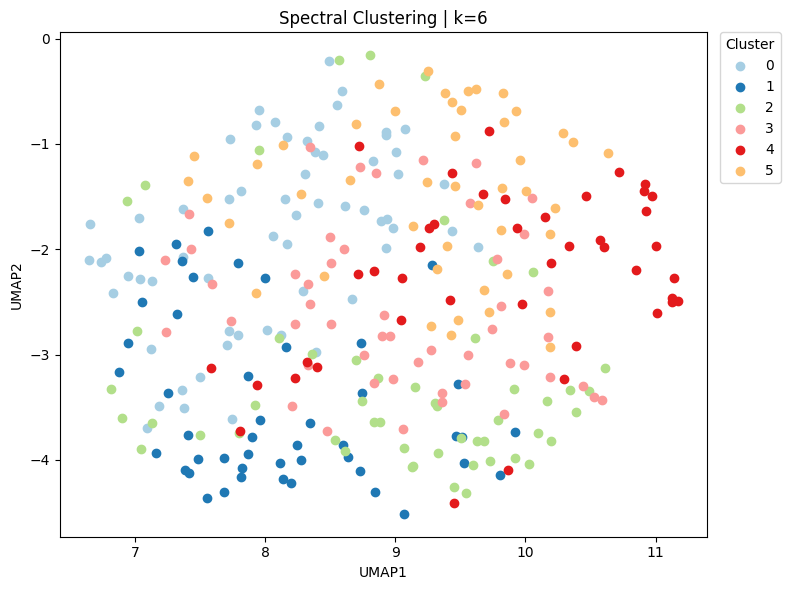

In [15]:
# Visualize 
hda.visualize.scatter(
    cluster=c1_spec_traj,
    embedding=em_traj_,
    title="Spectral Clustering | k=6",
    show_label=False
)

### PCA-based clusters 

gene x cell expression matrix -> PCA (cell x PC) -> distance matrix -> cluster

In [16]:
# PCA for representation - cell x PC matrix
hdata.compute_PCA(
    data=subset_traj_,
    key="X",
    kind="cell",
    n_pc=20
)

pc_matrix = hdata.layers["pca"]    

PCA matrix cell x 20 PCs stored in data.layers["pca"] 



In [17]:
# Compute traj-traj distance matrix in PC space
hdata.compute_similarity(
    data=subset_traj_,
    key="pca",
    kind="trajectory",
    trajectory_id=top_traj,
    method="correlation"
)

Similarity "correlation_pca_traj" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'pca']
  similarities: ['correlation_X_trajectory', 'correlation_pca_traj']
  clusters: ['spectral_k6_trajectory']
  embeddings: ['umap_trajectory_exp_dist']
  trajectories: Yes

In [18]:
sim_pca_traj = hdata.similarities["correlation_pca_traj"]

In [19]:
# Cluster in PC space
hdata.cluster_spectral(
    sim=sim_pca_traj,
    kind="trajectory",
    k=6
)

Cluster "spectral_k6_trajectory" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'pca']
  similarities: ['correlation_X_trajectory', 'correlation_pca_traj']
  clusters: ['spectral_k6_trajectory']
  embeddings: ['umap_trajectory_exp_dist']
  trajectories: Yes

In [20]:
cl_pca_traj_ = hdata.clusters["spectral_k6_trajectory"]

In [21]:
# Get UMAP embeddings
hdata.reduce_UMAP(
    data = subset_traj_,
    key = "pca",
    kind = "trajectory",
    trajectory_id=top_traj,
    id = "pc20"
)

UMAP embedding "umap_trajectory_pc20" stored! 



HDAData object with:
  n_vars (genes): 43750
  n_obs (cells): 7404
  X shape: (43750, 7404)
  layers: ['ntr', 'pca']
  similarities: ['correlation_X_trajectory', 'correlation_pca_traj']
  clusters: ['spectral_k6_trajectory']
  embeddings: ['umap_trajectory_exp_dist', 'umap_trajectory_pc20']
  trajectories: Yes

In [22]:
em_pca_traj_ = hdata.embeddings["umap_trajectory_pc20"]

#### PC = 20

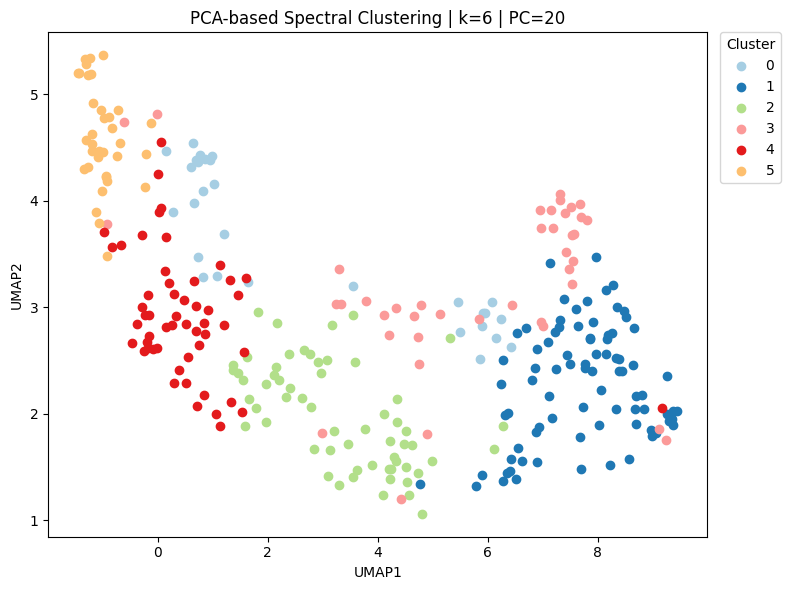

In [23]:
# Visualize 
hda.visualize.scatter(
    cluster=cl_pca_traj_,
    embedding=em_pca_traj_,
    title="PCA-based Spectral Clustering | k=6 | PC=20",
    show_label=False
)

## New RNA

In [ ]:
# # compute New RNA from X * ntr
# new_rna = subset_cells_.X.multiply(subset_cells_.layers["ntr"])

# # temporarily store the new RNA matrix in subset object layers
# subset_cells_.layers["new_rna"] = new_rna 

#### PC = 20

PCA matrix new_rna x 20 PCs stored in data.layers["pca"] 

Similarity "correlation_pca_cell" stored! 

Cluster "spectral_k6_cell" stored! 

UMAP embedding "umap_cell_pc20" stored! 



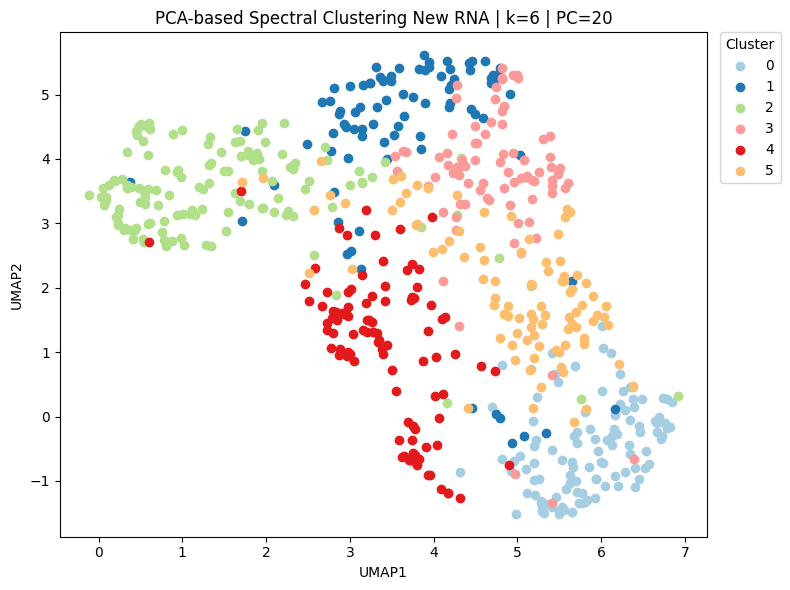

In [ ]:
# # PCA on new RNA
# hdata.compute_PCA(
#     data=subset_cells_,
#     key="new_rna",      
#     kind="cell",
#     n_pc=20
# )

# pc_matrix = hdata.layers["pca"]  

# # Compute cell-cell distance matrix in PC space
# hdata.compute_similarity(
#     data=subset_cells_,
#     key="pca",
#     method="correlation"
# )

# sim_pca_newrna_ = hdata.similarities["correlation_pca_cell"]   

# # Cluster in PC space
# hdata.cluster_spectral(
#     sim=sim_pca_newrna_,
#     kind="cell",
#     k=6
# )

# cl_pca_newrna_ = hdata.clusters["spectral_k6_cell"]

# # Get UMAP embeddings
# hdata.reduce_UMAP(
#     key = "pca",
#     kind = "cell",
#     id = "pc20"
# )

# em_pca_newrna_= hdata.embeddings["umap_cell_pc20"] 

# # Visualize 
# hda.visualize.scatter(
#     cluster=cl_pca_newrna_,
#     embedding=em_pca_newrna_,
#     title="PCA-based Spectral Clustering New RNA | k=6 | PC=20",
#     show_label=False
# )

![img6](temp/img6.jpg)